# Lab 09 — Generative action heads: from regression to flow matching

**Book sections:** [6.1](../../book/docs/chapters/06-generative/multimodality.md)–[6.6](../../book/docs/chapters/06-generative/sampling-cost.md).

**Goal.** One small, honest benchmark for every action model of Chapter 6. A robot must pass an obstacle:
demonstrations go left *or* right, and the two options differ in both action dimensions. We train MSE
regression, a mixture density network, discretised actions (independent and autoregressive), a conditional
VAE, a DDPM diffusion model and a flow-matching model on the same data, then compare how often their samples
land *between* the modes (an invalid action), whether they use both modes, and what each sample costs.

**Runtime:** ≈4 min on CPU. **Downloads:** none. **GPU:** not needed. **Seed:** 0.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from vlacourse.generative import Binner, fm_loss, fm_sample
from vlacourse.seed import set_seed

set_seed(0)
torch.set_num_threads(4)

## 1. The task and the failure of regression
Observation $o\in[-1,1]$: the obstacle's lateral offset. Action $\mathbf{a}=(a_\text{lat}, a_\text{fwd})$.
Demonstrators swerve **left**, $\mathbf{a}\approx(o-0.6,\ 0.4)$ (slower, around the tight side), or **right**,
$\mathbf{a}\approx(o+0.6,\ 0.9)$, with probability 1/2 each. A valid action is close to one of the two modes.

In [2]:
MODES = [(-0.6, 0.4), (0.6, 0.9)]


def demos(n, generator=None):
    o = torch.rand(n, 1, generator=generator) * 2 - 1
    side = torch.randint(0, 2, (n,), generator=generator)
    centre = torch.tensor(MODES)[side]                                   # (n, 2)
    a = torch.cat([o + centre[:, :1], centre[:, 1:]], 1) + 0.04 * torch.randn(n, 2, generator=generator)
    return o, a


def mode_stats(o, a):
    """Fraction of samples near the left mode, near the right mode, and near neither (invalid)."""
    d = torch.stack([((a - torch.cat([o + m[0], torch.full_like(o, m[1])], 1)) ** 2).sum(1).sqrt()
                     for m in MODES])                                     # (2, n)
    near = d.min(0).values < 0.15
    left = near & (d.argmin(0) == 0)
    return {"left": left.float().mean().item(), "right": (near & ~left).float().mean().item(),
            "invalid": (~near).float().mean().item()}


o_train, a_train = demos(20_000, torch.Generator().manual_seed(1))
o_test = torch.linspace(-0.8, 0.8, 9).repeat_interleave(200)[:, None]   # 1800 test observations


def mlp(d_in, d_out, h=128):
    return nn.Sequential(nn.Linear(d_in, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, d_out))


def train(loss_fn, params, steps=3000, bs=512, lr=2e-3):
    opt = torch.optim.Adam(params, lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        j = torch.randint(0, len(o_train), (bs,))
        loss = loss_fn(o_train[j], a_train[j])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return loss.item()


results, samples = {}, {}


def record(name, sample_fn, nfe):
    with torch.no_grad():
        t0 = time.perf_counter()
        a = sample_fn(o_test)
        dt = (time.perf_counter() - t0) / len(o_test) * 1e6
    samples[name] = a
    results[name] = {**mode_stats(o_test, a), "network evals": nfe, "µs/sample": round(dt, 2)}
    print(f"{name:28s} {results[name]}")


set_seed(0)
reg = mlp(1, 2)
train(lambda o, a: ((reg(o) - a) ** 2).mean(), reg.parameters())
record("MSE regression", reg, 1)

MSE regression               {'left': 0.0, 'right': 0.0, 'invalid': 1.0, 'network evals': 1, 'µs/sample': 0.59}


Regression predicts the conditional mean, $(o,\ 0.65)$ — between the modes, i.e. through the obstacle, every
single time (book 6.1).

## 2. Mixture density network
$K$ Gaussians whose weights, means and scales depend on $o$ (book 6.2). Sampling picks a component first.

In [3]:
class MDN(nn.Module):
    def __init__(self, K=5, d_a=2):
        super().__init__()
        self.K, self.d_a = K, d_a
        self.net = mlp(1, K * (1 + 2 * d_a))

    def forward(self, o):
        out = self.net(o)
        logit_pi, mu, log_s = out.split([self.K, self.K * self.d_a, self.K * self.d_a], -1)
        return logit_pi, mu.view(-1, self.K, self.d_a), log_s.view(-1, self.K, self.d_a).clamp(-6, 2)

    def nll(self, o, a):
        logit_pi, mu, log_s = self(o)
        z = (a[:, None] - mu) / log_s.exp()
        log_n = -0.5 * (z ** 2).sum(-1) - log_s.sum(-1) - self.d_a * 0.5 * math.log(2 * math.pi)
        return -torch.logsumexp(F.log_softmax(logit_pi, -1) + log_n, -1).mean()

    def sample(self, o):
        logit_pi, mu, log_s = self(o)
        k = torch.distributions.Categorical(logits=logit_pi).sample()
        i = torch.arange(len(o))
        return mu[i, k] + log_s[i, k].exp() * torch.randn(len(o), self.d_a)


for K in (2, 5):
    set_seed(0)
    mdn = MDN(K)
    train(mdn.nll, mdn.parameters())
    record(f"MDN, K={K}", mdn.sample, 1)
    with torch.no_grad():
        pi = F.softmax(mdn(torch.zeros(1, 1))[0], -1)[0]
    print("   mixture weights at o=0:", [round(p, 2) for p in pi.tolist()])

MDN, K=2                     {'left': 0.47611111402511597, 'right': 0.522777795791626, 'invalid': 0.0011111111380159855, 'network evals': 1, 'µs/sample': 1.04}
   mixture weights at o=0: [0.5, 0.5]


MDN, K=5                     {'left': 0.5066666603088379, 'right': 0.4927777647972107, 'invalid': 0.0005555555690079927, 'network evals': 1, 'µs/sample': 0.84}
   mixture weights at o=0: [0.5, 0.0, 0.0, 0.5, 0.0]


## 3. Discretised actions: independent vs autoregressive
32 bins per dimension on $[-2,2]\times[0,1.2]$. **Independent:** two categorical heads, one per dimension.
**Autoregressive:** the head for $a_\text{fwd}$ also receives the (one-hot) bin chosen for $a_\text{lat}$ —
exactly how a language model emits a multi-token action (book 6.2).

In [4]:
Kb = 32
binner = Binner([-2.0, 0.0], [2.0, 1.2], K=Kb)


class IndependentBins(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(1, 2 * Kb)

    def loss(self, o, a):
        k = binner.encode(a)
        logits = self.net(o).view(-1, 2, Kb)
        return F.cross_entropy(logits.reshape(-1, Kb), k.reshape(-1))

    def sample(self, o):
        k = torch.distributions.Categorical(logits=self.net(o).view(-1, 2, Kb)).sample()
        return binner.decode(k)


class AutoregressiveBins(nn.Module):
    def __init__(self):
        super().__init__()
        self.head1 = mlp(1, Kb)
        self.head2 = mlp(1 + Kb, Kb)

    def loss(self, o, a):
        k = binner.encode(a)
        l1 = F.cross_entropy(self.head1(o), k[:, 0])
        l2 = F.cross_entropy(self.head2(torch.cat([o, F.one_hot(k[:, 0], Kb).float()], -1)), k[:, 1])  # teacher forcing
        return l1 + l2

    def sample(self, o):
        k1 = torch.distributions.Categorical(logits=self.head1(o)).sample()
        k2 = torch.distributions.Categorical(logits=self.head2(torch.cat([o, F.one_hot(k1, Kb).float()], -1))).sample()
        return binner.decode(torch.stack([k1, k2], 1))


for name, cls, nfe in [("bins, independent", IndependentBins, 1), ("bins, autoregressive", AutoregressiveBins, 2)]:
    set_seed(0)
    m = cls()
    train(m.loss, m.parameters())
    record(name, m.sample, nfe)

bins, independent            {'left': 0.24944444000720978, 'right': 0.24388888478279114, 'invalid': 0.5066666603088379, 'network evals': 1, 'µs/sample': 2.53}


bins, autoregressive         {'left': 0.48055556416511536, 'right': 0.5083333253860474, 'invalid': 0.011111111380159855, 'network evals': 2, 'µs/sample': 3.12}


Independent bins sample the lateral and forward dimensions from different modes half the time —
"swerve left at the fast speed" — so roughly half the samples are invalid. Conditioning the second token on
the first restores coherence. (Quantisation: bin width 0.125 in $a_\text{lat}$; bin centres are within 0.0625
of the true value, inside our 0.15 validity radius.)

## 4. Conditional VAE (ACT's model)
Encoder $q_\phi(\mathbf{z}\mid\mathbf{a},o)$, decoder $D_\theta(o,\mathbf{z})$, ELBO with weight $\beta$ on the
KL (book 6.3). Watch the KL term: if it goes to zero, the latent is unused and the model is back to regression.

In [5]:
class CVAE(nn.Module):
    def __init__(self, d_z=2):
        super().__init__()
        self.d_z = d_z
        self.enc = mlp(1 + 2, 2 * d_z)
        self.dec = mlp(1 + d_z, 2)

    def terms(self, o, a):
        mu, log_var = self.enc(torch.cat([o, a], -1)).chunk(2, -1)
        z = mu + (0.5 * log_var).exp() * torch.randn_like(mu)
        recon = ((self.dec(torch.cat([o, z], -1)) - a) ** 2).sum(-1).mean()
        kl = 0.5 * (mu ** 2 + log_var.exp() - 1 - log_var).sum(-1).mean()
        return recon, kl

    def sample(self, o, zero=False):
        z = torch.zeros(len(o), self.d_z) if zero else torch.randn(len(o), self.d_z)
        return self.dec(torch.cat([o, z], -1))


for beta in (0.01, 1.0, 10.0):
    set_seed(0)
    cvae = CVAE()
    train(lambda o, a: (lambda r, k: r + beta * k)(*cvae.terms(o, a)), cvae.parameters())
    with torch.no_grad():
        r, k = cvae.terms(*demos(4000, torch.Generator().manual_seed(2)))
    print(f"beta={beta:5}: reconstruction {r:.4f}  KL {k:.4f}")
    record(f"CVAE, beta={beta}", cvae.sample, 1)
    if beta == 1.0:
        record("CVAE, beta=1, z=0 (ACT)", lambda o: cvae.sample(o, zero=True), 1)

beta= 0.01: reconstruction 0.0042  KL 1.2584
CVAE, beta=0.01              {'left': 0.40166667103767395, 'right': 0.39500001072883606, 'invalid': 0.20333333313465118, 'network evals': 1, 'µs/sample': 0.46}


beta=  1.0: reconstruction 0.4242  KL 0.0000
CVAE, beta=1.0               {'left': 0.0, 'right': 0.0, 'invalid': 1.0, 'network evals': 1, 'µs/sample': 0.51}
CVAE, beta=1, z=0 (ACT)      {'left': 0.0, 'right': 0.0, 'invalid': 1.0, 'network evals': 1, 'µs/sample': 0.28}


beta= 10.0: reconstruction 0.4243  KL 0.0000
CVAE, beta=10.0              {'left': 0.0, 'right': 0.0, 'invalid': 1.0, 'network evals': 1, 'µs/sample': 0.58}


With $\beta=0.01$ the latent encodes the side and sampling from the prior picks either mode — but about a
fifth of the samples come from regions of $\mathbf{z}$-space the encoder never used and decode to off-mode actions
("prior holes"). With $\beta=1$ and $\beta=10$ the KL is exactly zero: the encoder outputs the prior, the latent
carries nothing, and the decoder averages again — **posterior collapse**, at the textbook value $\beta=1$. ACT
survives with $\beta=10$ because its encoder sees a 100-step action chunk, whose information the decoder cannot
reconstruct without the latent; here a 2-D action is too easy to "explain" on average. With collapse, ACT's
$\mathbf{z}=\mathbf{0}$ is just regression.

## 5. DDPM diffusion, and DDIM with fewer steps
Noise-prediction network $\boldsymbol\epsilon_\theta(\mathbf{x}_k,k,o)$, $K=100$ (book 6.4).

In [6]:
Kd = 100
betas = torch.linspace(1e-4, 0.05, Kd)
ab = torch.cumprod(1 - betas, 0)


def emb(t, dim=16):                                       # sinusoidal features of a scalar in [0, 1]
    f = torch.exp(-math.log(1000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None] * 1000 * f
    return torch.cat([a.sin(), a.cos()], -1)


eps_net = mlp(2 + 1 + 16, 2, h=256)


def eps_model(x, k, o):
    return eps_net(torch.cat([x, o, emb(k.float() / Kd)], -1))


def ddpm_loss(o, a):
    k = torch.randint(0, Kd, (len(a),))
    e = torch.randn_like(a)
    abk = ab[k][:, None]
    return ((eps_model(abk.sqrt() * a + (1 - abk).sqrt() * e, k, o) - e) ** 2).mean()


def ddpm_sample(o):
    x = torch.randn(len(o), 2)
    for k in reversed(range(Kd)):
        kk = torch.full((len(o),), k)
        x = (x - betas[k] / (1 - ab[k]).sqrt() * eps_model(x, kk, o)) / (1 - betas[k]).sqrt()
        if k > 0:
            x = x + betas[k].sqrt() * torch.randn_like(x)
    return x


def ddim_sample(o, n_steps):
    ks = torch.linspace(Kd - 1, 0, n_steps).round().long()
    x = torch.randn(len(o), 2)
    for i, k in enumerate(ks):
        e = eps_model(x, torch.full((len(o),), int(k)), o)
        x0 = (x - (1 - ab[k]).sqrt() * e) / ab[k].sqrt()
        ab_prev = ab[ks[i + 1]] if i + 1 < len(ks) else torch.tensor(1.0)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * e
    return x


set_seed(0)
t0 = time.time()
train(ddpm_loss, eps_net.parameters(), steps=6000, lr=1e-3)
print(f"trained in {time.time() - t0:.0f} s")
record("DDPM, 100 steps", ddpm_sample, 100)
for n in (10, 5, 2):
    record(f"DDIM, {n} steps", lambda o, n=n: ddim_sample(o, n), n)

trained in 12 s
DDPM, 100 steps              {'left': 0.4811111092567444, 'right': 0.4672222137451172, 'invalid': 0.05166666582226753, 'network evals': 100, 'µs/sample': 88.69}
DDIM, 10 steps               {'left': 0.5211111307144165, 'right': 0.40666666626930237, 'invalid': 0.07222222536802292, 'network evals': 10, 'µs/sample': 13.6}
DDIM, 5 steps                {'left': 0.38777777552604675, 'right': 0.3616666793823242, 'invalid': 0.25055554509162903, 'network evals': 5, 'µs/sample': 6.52}


DDIM, 2 steps                {'left': 0.0027777778450399637, 'right': 0.018333332613110542, 'invalid': 0.9788888692855835, 'network evals': 2, 'µs/sample': 2.32}


## 6. Flow matching
Velocity network $\mathbf{v}_\theta(\mathbf{x}_\tau,\tau,o)$, straight paths from noise to data, Euler sampling
(book 6.5). `fm_loss` and `fm_sample` are the two functions in `vlacourse.generative`.

In [7]:
v_net = mlp(2 + 1 + 16, 2, h=256)


def v_model(x, tau, o):
    return v_net(torch.cat([x, o, emb(tau)], -1))


set_seed(0)
t0 = time.time()
train(lambda o, a: fm_loss(v_model, a, o), v_net.parameters(), steps=6000, lr=1e-3)
print(f"trained in {time.time() - t0:.0f} s")
for n in (1, 2, 5, 10, 50):
    record(f"flow matching, {n} step{'s' * (n > 1)}", lambda o, n=n: fm_sample(v_model, o, (len(o), 2), steps=n), n)

trained in 12 s
flow matching, 1 step        {'left': 0.0011111111380159855, 'right': 0.0, 'invalid': 0.9988889098167419, 'network evals': 1, 'µs/sample': 2.1}
flow matching, 2 steps       {'left': 0.04777777940034866, 'right': 0.04555555433034897, 'invalid': 0.9066666960716248, 'network evals': 2, 'µs/sample': 3.02}
flow matching, 5 steps       {'left': 0.4188888967037201, 'right': 0.4077777862548828, 'invalid': 0.1733333319425583, 'network evals': 5, 'µs/sample': 7.14}
flow matching, 10 steps      {'left': 0.45222222805023193, 'right': 0.46611112356185913, 'invalid': 0.08166666328907013, 'network evals': 10, 'µs/sample': 14.03}
flow matching, 50 steps      {'left': 0.48444443941116333, 'right': 0.4772222340106964, 'invalid': 0.038333334028720856, 'network evals': 50, 'µs/sample': 68.59}


## 7. Everything side by side
Samples for $o=0$ (the obstacle straight ahead), and the summary table.

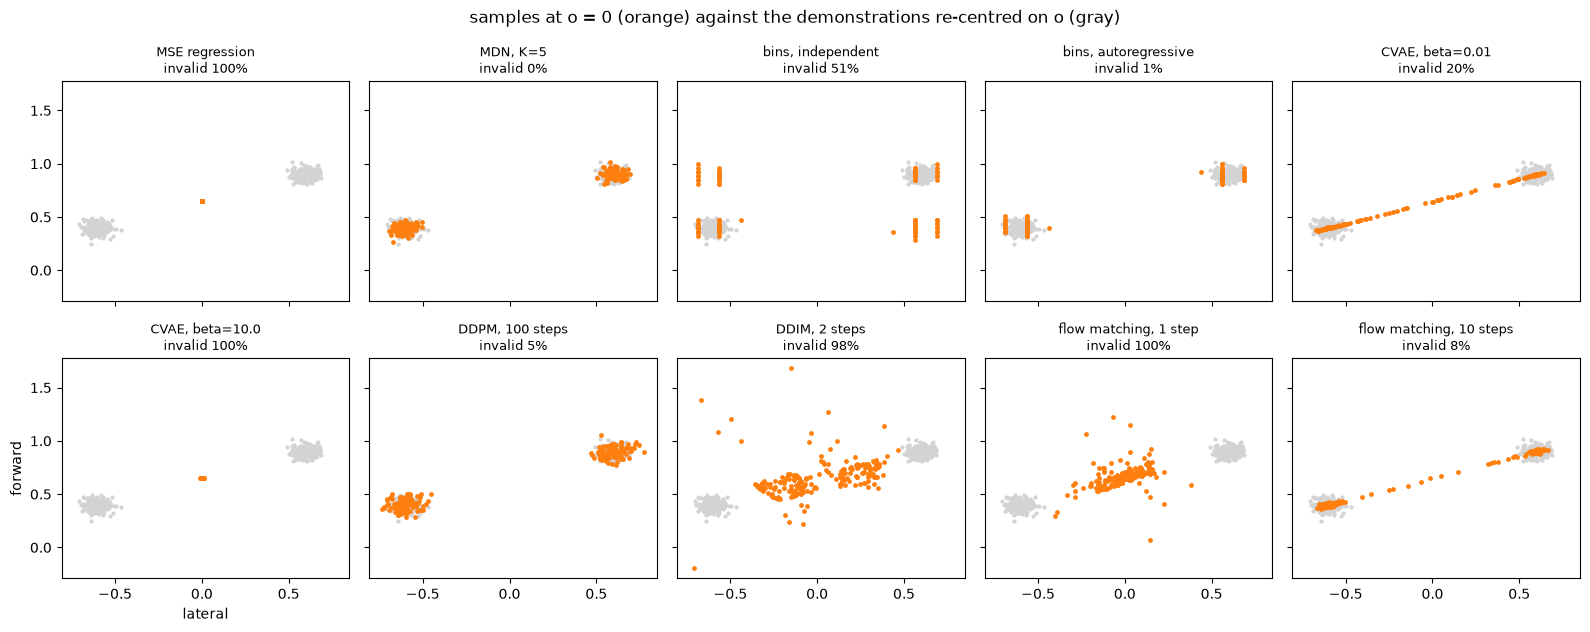

model                          left  right  invalid  evals  µs/sample
MSE regression                 0.00   0.00     1.00      1        0.6
MDN, K=2                       0.48   0.52     0.00      1        1.0
MDN, K=5                       0.51   0.49     0.00      1        0.8
bins, independent              0.25   0.24     0.51      1        2.5
bins, autoregressive           0.48   0.51     0.01      2        3.1
CVAE, beta=0.01                0.40   0.40     0.20      1        0.5
CVAE, beta=1.0                 0.00   0.00     1.00      1        0.5
CVAE, beta=1, z=0 (ACT)        0.00   0.00     1.00      1        0.3
CVAE, beta=10.0                0.00   0.00     1.00      1        0.6
DDPM, 100 steps                0.48   0.47     0.05    100       88.7
DDIM, 10 steps                 0.52   0.41     0.07     10       13.6
DDIM, 5 steps                  0.39   0.36     0.25      5        6.5
DDIM, 2 steps                  0.00   0.02     0.98      2        2.3
flow matching, 1 ste

In [8]:
show = ["MSE regression", "MDN, K=5", "bins, independent", "bins, autoregressive", "CVAE, beta=0.01",
        "CVAE, beta=10.0", "DDPM, 100 steps", "DDIM, 2 steps", "flow matching, 1 step", "flow matching, 10 steps"]
mid = (o_test[:, 0].abs() < 1e-6)
fig, axs = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True, sharey=True)
for ax, name in zip(axs.flat, show):
    _, a_demo = demos(400, torch.Generator().manual_seed(3))
    ax.scatter(a_demo[:, 0] - _[:, 0], a_demo[:, 1], s=4, c="lightgray")
    a = samples[name][mid]
    ax.scatter(a[:, 0], a[:, 1], s=6, c="tab:orange")
    ax.set_title(f"{name}\ninvalid {results[name]['invalid']:.0%}", fontsize=9)
axs[1, 0].set_xlabel("lateral"); axs[1, 0].set_ylabel("forward")
plt.suptitle("samples at o = 0 (orange) against the demonstrations re-centred on o (gray)")
plt.tight_layout(); plt.show()

print(f"{'model':28s} {'left':>6} {'right':>6} {'invalid':>8} {'evals':>6} {'µs/sample':>10}")
for name, r in results.items():
    print(f"{name:28s} {r['left']:6.2f} {r['right']:6.2f} {r['invalid']:8.2f} {r['network evals']:6d} {r['µs/sample']:10.1f}")

Read the table with Chapter 6 in mind:

* **Regression** is always invalid here; the averaging argument of 6.1 in one row.
* **MDN** and **autoregressive bins** are coherent and cheap, because the mode is chosen *explicitly* (a
  component, a first token) before the rest. **Independent bins** are not.
* The **CVAE** depends on $\beta$: too small leaves prior holes, too large collapses.
* **Diffusion** and **flow matching** need no choice of the number of modes. With enough steps both are
  accurate (a few percent invalid). With 5 steps flow matching degrades less than DDIM; with 10 they are
  similar; with 1–2 steps both fail — one Euler step from noise moves every sample by the *average* velocity,
  which is regression again. Fewer steps is never free (book 6.6).
* Cost is network evaluations × network size. On a robot, multiply by the backbone in front (book 6.6).

## 8. Trajectories of the flow
Integrate the flow from 30 noise samples at $o=0$ with 50 steps and draw $a_\text{lat}$ against flow time.

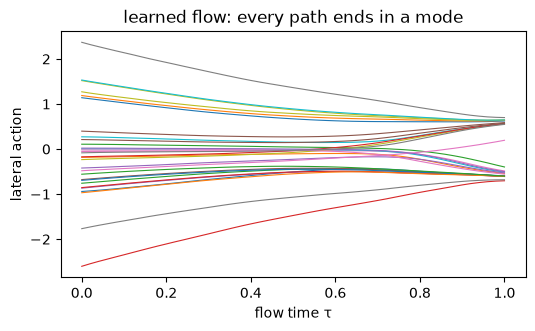

In [9]:
with torch.no_grad():
    o0 = torch.zeros(30, 1)
    x = torch.randn(30, 2, generator=torch.Generator().manual_seed(4))
    path = [x.clone()]
    for i in range(50):
        x = x + v_model(x, torch.full((30,), i / 50), o0) / 50
        path.append(x.clone())
P = torch.stack(path)
plt.figure(figsize=(6, 3.2))
for j in range(30):
    plt.plot(np.linspace(0, 1, 51), P[:, j, 0], lw=0.8)
plt.xlabel("flow time τ"); plt.ylabel("lateral action"); plt.title("learned flow: every path ends in a mode")
plt.show()

## Exercises
1. Make the modes unequal (80% left, 20% right). Which models reproduce the 80/20 split? Which collapse to
   the majority mode?
2. Increase the action to a chunk of 8 future steps (16 dimensions) with smooth trajectories. How many tokens
   does the autoregressive bin model need? Which models degrade first?
3. Distil the 50-step flow into a 1-step student by regressing its endpoints from the same noise (a
   simplified *reflow*). How invalid is the student?
4. Time `fm_sample` with 10 steps on a GPU at batch size 1. What fraction is Python/kernel-launch overhead?
   (Compare with book 2.6's observations on small-model decode.)
5. Robotics: at $o=0$, sample an action every control step with fresh noise. How often does the robot switch
   side between consecutive steps? Propose two fixes (book 6.6, Chapter 8).